# Phase 8 - Probability calibration and conformal uncertainty

Goal: make the final model's confidence trustworthy and give uncertain returns a principled route to review.

- **Final model: taken from Phase 7.** The notebook reads `reports/phase7_config.json` (the final model and, if an ensemble had been kept, its members and weights), rebuilds that model for **three seeds** and checks seed 0 against `phase7_validation_predictions.csv`. In the current Phase 7 result no ensemble was kept, so the final model is the best single model, CatBoost.
- **8.1 Calibration:** Platt scaling (sigmoid), isotonic regression and a smoother **bagged isotonic** regression, each **fitted only on the 10% calibration part**. The calibrator is **chosen on the calibration part itself by 5-fold cross-fitting**, not on the validation window; the May-June validation period is then used only to report. Reported with the Brier score, ECE, reliability plots and the official score of the routing each calibrator produces. Calibration is also checked inside every customer group.
- **8.2 Conformal prediction:** split conformal, its Mondrian (per-class) variant and a **recency-weighted** Mondrian variant give each return a set of plausible classes, for example {genuine_fit_issue} or {abusive, genuine_wrong_item}. Coverage is checked overall (with and without the empty-set fix), per class, per week and month, per subgroup, and the calibration and validation score distributions are compared to look for drift.
- A prediction set is **not** a calibrated probability, and its coverage guarantee only holds when calibration and later data are similar; the notebook measures that instead of assuming it.
- July-September labels are never used.

**How to run:** keep this file in `FULL_CODE/notebooks/`, run Phases 5 and 7 first (this notebook needs their saved reports), and use the project environment. About 6 minutes.

In [1]:
import json
import platform
import sys
from pathlib import Path

for candidate_path in (Path('../src'), Path('src')):
    if candidate_path.exists():
        sys.path.insert(0, str(candidate_path.resolve()))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.stats import ks_2samp
from sklearn.metrics import brier_score_loss, log_loss

from r2sorter.advanced import fit_lgbm
from r2sorter.baselines import build_model, catboost_inputs, expected_calibration_error, predict_full, reliability_table
from r2sorter.calibration import AbuseCalibrator
from r2sorter.config import load_config
from r2sorter.conformal import (coverage, cross_fit_calibrated, ensure_nonempty, fit_thresholds, fit_thresholds_weighted, prediction_sets,
                                recency_weights, rescale_four_class, set_labels, wilson_interval)
from r2sorter.data import LABELS, load_all
from r2sorter.ensemble import blend, evaluate_routing, fairness_masks, fast_official
from r2sorter.nlp import language_group3
from r2sorter.protocol import TEXT_COLUMNS, build_protocol
from r2sorter.router import route

pd.set_option('display.width', 220, 'display.max_columns', 50, 'display.max_colwidth', 70)
AB = LABELS.index('abusive')
SEEDS = (0, 1, 2)
MAIN_ALPHA = 0.10
ALPHAS = (0.05, 0.10, 0.20)
HALF_LIFE_DAYS = 14        # recency weighting of the calibration rows for the weighted conformal variant
cfg = load_config()
data = load_all(cfg)
REPORTS = Path('../reports') if Path('../reports').exists() else Path('reports')
MODELS = REPORTS.parent / 'models' / 'phase8'
FIG = REPORTS / 'figures'
for folder in (REPORTS, MODELS, FIG):
    folder.mkdir(parents=True, exist_ok=True)
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__}
print(versions)

{'python': '3.13.17', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1'}


## 1. The final model's predictions (three seeds)
Same protocol as Phases 5-7. The calibration part (4,388 requests, about 290 abusive) is held out from training and used only for calibration and the conformal thresholds. The validation period (May-June) is used only for evaluation. Seed 0 is the main run (it must reproduce Phase 7 exactly); seeds 1 and 2 show how much the results move.

In [2]:
protocol = build_protocol(cfg, data)
parts, y_idx, y_abuse = protocol.parts, protocol.y_index, protocol.y_abuse
x_train, x_cal, x_test = (protocol.matrix('tree', p) for p in ('train', 'calibration', 'test'))
cb_train, cat_names = catboost_inputs(x_train)
cb_cal, cb_test = catboost_inputs(x_cal)[0], catboost_inputs(x_test)[0]

config7_path = REPORTS / 'phase7_config.json'
config7 = json.loads(config7_path.read_text()) if config7_path.exists() else {'final_model': 'catboost'}
final_model_name = config7['final_model']
print('Phase 7 final model:', final_model_name, '| ensemble kept:', config7.get('ensemble_kept', False))

def text_probs(frame):
    block = frame[TEXT_COLUMNS].to_numpy(dtype=float)
    return block / block.sum(axis=1, keepdims=True)

def fit_member(name, seed):
    # returns (calibration probabilities, validation probabilities, fitted model or None)
    if name == 'catboost':
        model = build_model('catboost', seed, cat_names)
        model.fit(cb_train, y_idx['train'])
        return predict_full(model, cb_cal), predict_full(model, cb_test), model
    if name == 'text_logreg':
        return text_probs(x_cal), text_probs(x_test), None
    model = fit_lgbm(name.replace('lightgbm_', ''), seed, x_train, y_idx['train'])
    return predict_full(model, x_cal), predict_full(model, x_test), model

if final_model_name.startswith('ensemble'):
    weights = {n: w for n, w in config7['weights'].items() if w > 0}
    member_names = list(weights)
    member_weights = np.array([weights[n] for n in member_names])
    member_weights = member_weights / member_weights.sum()
else:
    member_names, member_weights = [final_model_name], np.ones(1)

def build_final(seed):
    fitted = {n: fit_member(n, seed) for n in member_names}
    return (blend([fitted[n][0] for n in member_names], member_weights), blend([fitted[n][1] for n in member_names], member_weights), fitted)

final_by_seed = {seed: build_final(seed) for seed in SEEDS}
probs_cal, probs_test, fitted_members = final_by_seed[0]
raw_cal, raw_test = probs_cal[:, AB], probs_test[:, AB]
y_cal, y_test = y_abuse['calibration'], y_abuse['test']
y_cal4, y_test4 = y_idx['calibration'], y_idx['test']
print('members:', dict(zip(member_names, member_weights.round(3).tolist())))
print('calibration rows', len(y_cal), '| abusive', int(y_cal.sum()), '| validation rows', len(y_test), '| abusive', int(y_test.sum()))
phase7 = REPORTS / 'phase7_validation_predictions.csv'
if phase7.exists():
    saved = pd.read_csv(phase7)
    assert saved['return_id'].tolist() == parts['test']['return_id'].tolist(), 'Phase 7 rows differ from this protocol'
    difference = float(np.abs(saved['p_abusive_raw'].to_numpy() - raw_test).max())
    print('largest difference to the Phase 7 raw P(abusive) of the final model (seed 0):', difference)
    assert difference < 1e-6, 'the rebuilt final model differs from Phase 7: check package versions'
else:
    print('Phase 7 predictions not found: comparison skipped')

Phase 7 final model: catboost | ensemble kept: False


members: {'catboost': 1.0}
calibration rows 4388 | abusive 287 | validation rows 8497 | abusive 699
largest difference to the Phase 7 raw P(abusive) of the final model (seed 0): 3.3306690738754696e-16


## 2. Choosing the calibrator without using the validation window
Three calibrators are compared, each fitted on the **calibration part only**: Platt scaling (2 parameters), isotonic regression (a step function that can overfit small data) and **bagged isotonic regression** (the average of 50 bootstrap isotonic fits: smoother and more stable).
To choose among them without looking at May-June, each calibrator is scored on the calibration part itself by **5-fold cross-fitting** (every row is calibrated by a calibrator that never saw it). Rule fixed beforehand: lowest cross-fit Brier score; calibrators within 0.0005 of the best Brier count as tied and the one whose routing earns the best official score wins, because the router is what uses the probability.

In [3]:
LABEL_TO_METHOD = {'Platt (sigmoid)': 'sigmoid', 'isotonic': 'isotonic', 'bagged isotonic': 'bagged_isotonic'}
masks_cal = fairness_masks(parts['calibration'], cfg)
select_rows = []
for label, method in LABEL_TO_METHOD.items():
    p_cf = cross_fit_calibrated(raw_cal, y_cal, method, folds=5)
    scored = fast_official(p_cf, y_cal, masks_cal, cfg)
    select_rows.append({'calibrator': label, 'brier': brier_score_loss(y_cal, p_cf), 'ece': expected_calibration_error(y_cal, p_cf),
                        'official_score': scored['primary'], 'fairness': scored['fairness'], 'saving': scored['savings'],
                        'distinct_values': int(len(np.unique(p_cf)))})
raw_scored = fast_official(raw_cal, y_cal, masks_cal, cfg)
select_rows.insert(0, {'calibrator': 'raw (uncalibrated)', 'brier': brier_score_loss(y_cal, raw_cal), 'ece': expected_calibration_error(y_cal, raw_cal),
                       'official_score': raw_scored['primary'], 'fairness': raw_scored['fairness'], 'saving': raw_scored['savings'],
                       'distinct_values': int(len(np.unique(raw_cal)))})
selection = pd.DataFrame(select_rows).set_index('calibrator')
calibrator_rows = selection.loc[list(LABEL_TO_METHOD)]
tied = calibrator_rows[calibrator_rows['brier'] <= calibrator_rows['brier'].min() + 0.0005]
chosen = tied['official_score'].idxmax() if len(tied) > 1 else tied.index[0]
chosen_method = LABEL_TO_METHOD[chosen]
reason = f'{len(tied)} calibrators tied on cross-fit Brier (within 0.0005): best official score' if len(tied) > 1 else 'lowest cross-fit Brier score'
selection.round(4).to_csv(REPORTS / 'phase8_calibrator_selection_calibration_part.csv')
print('chosen calibrator:', chosen, '|', reason, '(selected on the calibration part, cross-fitted)')
selection.round(4)

chosen calibrator: Platt (sigmoid) | lowest cross-fit Brier score (selected on the calibration part, cross-fitted)


,brier,ece,official_score,fairness,saving,distinct_values
calibrator,,,,,,
raw (uncalibrated),0.0382,0.0136,0.2960,0.6921,0.2251,4388
Platt (sigmoid),0.0383,0.0079,0.2870,0.6997,0.2101,4170
isotonic,0.0390,0.0058,0.2087,0.6250,0.1575,115
bagged isotonic,0.0390,0.0064,0.2289,0.6269,0.1725,669


## 3. Reporting the three calibrators on the validation window
Now each calibrator is fitted on the whole calibration part and applied to the May-June validation requests. Lower Brier, log-loss and ECE are better. ECE uses ten equal-mass bins; its 95% interval comes from 300 bootstrap resamples of the validation requests. This table is for **reporting**; it did not choose the calibrator.

In [4]:
calibrators = {label: AbuseCalibrator(method).fit(raw_cal, y_cal) for label, method in LABEL_TO_METHOD.items()}
candidates = {'raw (uncalibrated)': raw_test, **{name: c.transform(raw_test) for name, c in calibrators.items()}}
rng = np.random.default_rng(0)
boot = [rng.integers(0, len(y_test), len(y_test)) for _ in range(300)]
rows = []
for name, p in candidates.items():
    ece_draws = [expected_calibration_error(y_test[i], p[i]) for i in boot]
    routed = evaluate_routing(name, probs_test, p, parts['test'], y_test, cfg)
    rows.append({'probability': name, 'brier': brier_score_loss(y_test, p), 'log_loss': log_loss(y_test, np.clip(p, 1e-6, 1 - 1e-6)),
                 'ece': expected_calibration_error(y_test, p), 'ece_95%_low': np.quantile(ece_draws, 0.025), 'ece_95%_high': np.quantile(ece_draws, 0.975),
                 'distinct_values': int(len(np.unique(p))), 'official_score': routed['official_score'], 'fairness': routed['fairness_score'],
                 'cost_per_request': routed['cost_per_request'], 'saving_vs_approve_all': routed['saving_vs_approve_all'],
                 'genuine_escalated': routed['genuine_escalated']})
calibration_table = pd.DataFrame(rows).set_index('probability').round(4)
calibration_table.to_csv(REPORTS / 'phase8_calibration_comparison.csv')
final_calibrator = calibrators[chosen]
p_test_cal = candidates[chosen]
four_cal = rescale_four_class(probs_test, p_test_cal)
top_raw = expected_calibration_error((probs_test.argmax(axis=1) == y_test4).astype(float), probs_test.max(axis=1))
top_cal = expected_calibration_error((four_cal.argmax(axis=1) == y_test4).astype(float), four_cal.max(axis=1))
print(f'top-label ECE (the largest of the four probabilities): {top_raw:.4f} raw -> {top_cal:.4f} after rescaling around the calibrated P(abusive)')
calibration_table

top-label ECE (the largest of the four probabilities): 0.0104 raw -> 0.0084 after rescaling around the calibrated P(abusive)


,brier,log_loss,ece,ece_95%_low,ece_95%_high,distinct_values,official_score,fairness,cost_per_request,saving_vs_approve_all,genuine_escalated
probability,,,,,,,,,,,
raw (uncalibrated),0.0404,0.1472,0.0158,0.0126,0.0210,8497,0.3538,0.6983,0.0571,0.3059,0
Platt (sigmoid),0.0407,0.1470,0.0140,0.0118,0.0186,8151,0.3326,0.6577,0.0586,0.2873,1
isotonic,0.0410,0.1481,0.0134,0.0098,0.0180,67,0.3631,0.7345,0.0569,0.3089,1
bagged isotonic,0.0408,0.1476,0.0132,0.0101,0.0186,755,0.3524,0.6983,0.0573,0.3039,1


In [5]:
# the same chosen calibrator for every seed: does the result move?
seed_rows = []
for seed, (pc, pt, _) in final_by_seed.items():
    p_seed = AbuseCalibrator(chosen_method).fit(pc[:, AB], y_cal).transform(pt[:, AB])
    routed = evaluate_routing(f'seed {seed}', pt, p_seed, parts['test'], y_test, cfg)
    seed_rows.append({'seed': seed, 'brier': brier_score_loss(y_test, p_seed), 'ece': expected_calibration_error(y_test, p_seed),
                      'official_score': routed['official_score'], 'fairness': routed['fairness_score'], 'saving': routed['saving_vs_approve_all'],
                      'genuine_escalated': routed['genuine_escalated']})
seed_table = pd.DataFrame(seed_rows).set_index('seed')
seed_table.loc['mean'] = seed_table.mean()
seed_table.loc['sd'] = seed_table.iloc[:len(SEEDS)].std()
seed_table.round(4)

,brier,ece,official_score,fairness,saving,genuine_escalated
seed,,,,,,
0,0.0407,0.0140,0.3326,0.6577,0.2873,1
1,0.0414,0.0137,0.3423,0.7237,0.2823,1
2,0.0411,0.0133,0.3380,0.6932,0.2848,1
mean,0.0411,0.0137,0.3377,0.6915,0.2848,1
sd,0.0003,0.0003,0.0048,0.0330,0.0025,0


## 4. Reliability plots
Each point is one equal-mass bin of validation requests: mean predicted P(abusive) against the observed abusive rate. Points on the diagonal are well calibrated. The right panel zooms into the low range where most requests sit.

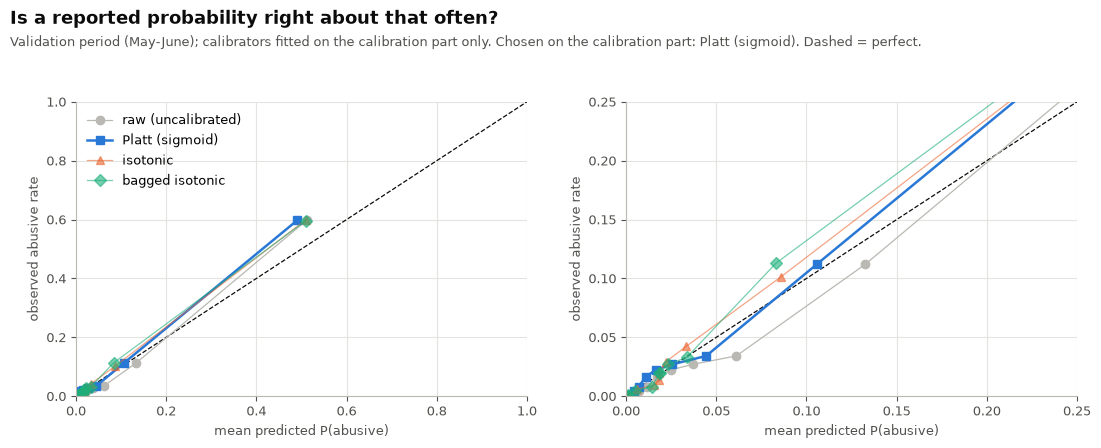

In [6]:
INK, MUTED, GRID, GREY = '#0b0b0b', '#52514e', '#e4e3df', '#b9b8b2'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'

def style(ax, grid_axis='both'):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GREY)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

styles = {'raw (uncalibrated)': (GREY, 'o'), 'Platt (sigmoid)': (BLUE, 's'), 'isotonic': (ORANGE, '^'), 'bagged isotonic': (AQUA, 'D')}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
fig.subplots_adjust(top=0.78, left=0.07, right=0.98, bottom=0.14, wspace=0.22)
for ax, zoom in zip(axes, (False, True)):
    top = 1.0 if not zoom else 0.25
    ax.plot([0, top], [0, top], color=INK, linewidth=0.9, linestyle='--')
    for name, p in candidates.items():
        table = reliability_table(y_test, p, bins=10)
        colour, marker = styles[name]
        ax.plot(table['mean_predicted'], table['observed_rate'], color=colour, marker=marker, linewidth=1.8 if name == chosen else 0.9,
                alpha=1.0 if name in (chosen, 'raw (uncalibrated)') else 0.6, label=name)
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_xlabel('mean predicted P(abusive)', color=MUTED, fontsize=9)
    ax.set_ylabel('observed abusive rate', color=MUTED, fontsize=9)
    style(ax)
axes[0].legend(frameon=False, fontsize=9, loc='upper left')
fig.text(0.01, 0.98, 'Is a reported probability right about that often?', fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.925, f'Validation period (May-June); calibrators fitted on the calibration part only. Chosen on the calibration part: {chosen}. Dashed = perfect.', fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase8_reliability.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Is the confidence equally reliable for every group?
Calibration is checked inside each group (validation period, chosen calibrator, five equal-mass bins because the groups are smaller). The Wilson 95% interval of the observed abusive rate is compared with the mean predicted probability; `check` says whether the prediction lies outside that interval. Calibration is checked and flagged here, not forced: fitting separate calibrators per group would use group membership in the decision and is a policy choice for Phase 9. Language groups are a word-list heuristic with three levels (English-like, Hinglish-like mixed, Hindi-dominant transliterated); it is not a trained language identifier, and its Hindi share is a lower bound because the marker list is incomplete.

In [7]:
frame = parts['test']
tercile_edges = parts['train']['order_value_inr'].quantile([1 / 3, 2 / 3]).to_numpy()
language = language_group3(frame['customer_reason'])
week = frame['return_request_date'].dt.to_period('W').astype(str)
groups = {
    f"customer: new (< {cfg['fairness']['new_customer_days']} days)": frame['customer_tenure_days'] < cfg['fairness']['new_customer_days'],
    'customer: established': frame['customer_tenure_days'] >= cfg['fairness']['new_customer_days'],
    'order value: low third': frame['order_value_inr'] < tercile_edges[0],
    'order value: middle third': (frame['order_value_inr'] >= tercile_edges[0]) & (frame['order_value_inr'] < tercile_edges[1]),
    'order value: high third': frame['order_value_inr'] >= tercile_edges[1],
    'text: English-like': language == 'english_like',
    'text: Hinglish-like (mixed)': language == 'hinglish_like',
    'text: Hindi-dominant': language == 'hindi_dominant',
    'month: May': frame['return_request_date'].dt.to_period('M').astype(str) == '2026-05',
    'month: June': frame['return_request_date'].dt.to_period('M').astype(str) == '2026-06',
}
group_rows = []
for name, mask in groups.items():
    mask = np.asarray(mask)
    y_g, p_g = y_test[mask], p_test_cal[mask]
    low, high = wilson_interval(y_g.sum(), int(mask.sum()))
    group_rows.append({'group': name, 'requests': int(mask.sum()), 'abusive': int(y_g.sum()), 'mean_predicted': p_g.mean(), 'observed_rate': y_g.mean(),
                       'observed_95%_low': low, 'observed_95%_high': high, 'check': 'ok' if low <= p_g.mean() <= high else 'prediction outside interval',
                       'brier': brier_score_loss(y_g, p_g), 'ece_5_bins': expected_calibration_error(y_g, p_g, bins=5)})
group_calibration = pd.DataFrame(group_rows).set_index('group').round(4)
group_calibration.to_csv(REPORTS / 'phase8_group_calibration.csv')
print('language group sizes:', language.value_counts().to_dict())
group_calibration

language group sizes: {'english_like': 4440, 'hindi_dominant': 2331, 'hinglish_like': 1726}


,requests,abusive,mean_predicted,observed_rate,observed_95%_low,observed_95%_high,check,brier,ece_5_bins
group,,,,,,,,,
customer: new (< 90 days),1111,90,0.0586,0.0810,0.0664,0.0985,prediction outside interval,0.0431,0.0263
customer: established,7386,609,0.0726,0.0825,0.0764,0.0889,prediction outside interval,0.0404,0.0122
order value: low third,2624,191,0.0619,0.0728,0.0635,0.0834,prediction outside interval,0.0378,0.0112
order value: middle third,2942,229,0.0658,0.0778,0.0687,0.0881,prediction outside interval,0.0396,0.0168
order value: high third,2931,279,0.0838,0.0952,0.0851,0.1064,prediction outside interval,0.0444,0.0200
text: English-like,4440,383,0.0701,0.0863,0.0784,0.0949,prediction outside interval,0.0428,0.0164
text: Hinglish-like (mixed),1726,127,0.0733,0.0736,0.0622,0.0869,ok,0.0339,0.0146
text: Hindi-dominant,2331,189,0.0702,0.0811,0.0707,0.0929,prediction outside interval,0.0418,0.0144
month: May,3729,320,0.0722,0.0858,0.0772,0.0952,prediction outside interval,0.0412,0.0176


## 6. Conformal prediction sets
Scores are 1 - P(true class), computed from the calibrated four-class probabilities. To avoid a calibrator being judged on the very rows it was fitted on, the **calibration rows' probabilities come from a 5-fold cross-fitted calibrator**; validation rows use the calibrator fitted on the whole calibration part.
Three variants are compared at three error levels:
- **Marginal split conformal:** one threshold; guarantees the overall coverage only.
- **Mondrian:** one threshold per true class; aims at the target coverage for every class, including the rare abusive class.
- **Recency-weighted Mondrian:** like Mondrian, but newer calibration rows count more (half-life 14 days), which tracks drift between the calibration period and the later data better when the data are not exchangeable.

An empty set receives its most probable class, which can only raise coverage; coverage **before** that fix and the share of empty sets are reported so the effect is visible.

In [8]:
def prepare(pc, pt):
    # calibrated four-class probabilities: cross-fitted for the calibration rows, whole-part calibrator for the validation rows
    cal_cf = cross_fit_calibrated(pc[:, AB], y_cal, chosen_method, folds=5)
    p_val = AbuseCalibrator(chosen_method).fit(pc[:, AB], y_cal).transform(pt[:, AB])
    return rescale_four_class(pc, cal_cf), rescale_four_class(pt, p_val), p_val

prepared = {seed: prepare(pc, pt) for seed, (pc, pt, _) in final_by_seed.items()}
four_cal_calpart, four_cal, p_test_cal = prepared[0]
cal_weights = recency_weights(parts['calibration']['return_request_date'], HALF_LIFE_DAYS)
VARIANTS = {'marginal split': (False, False), 'Mondrian (per class)': (True, False), 'Mondrian, recency-weighted': (True, True)}

def build_sets(four_c, four_t, alpha, mondrian, weighted):
    thresholds = (fit_thresholds_weighted(four_c, y_cal4, cal_weights, alpha, mondrian) if weighted else fit_thresholds(four_c, y_cal4, alpha, mondrian))
    raw_sets = prediction_sets(four_t, thresholds)
    sets, empty_share = ensure_nonempty(raw_sets, four_t)
    return sets, raw_sets, thresholds, empty_share

conformal_rows, sets_by = [], {}
for alpha in ALPHAS:
    for label, (mondrian, weighted) in VARIANTS.items():
        sets, raw_sets, thresholds, empty_share = build_sets(four_cal_calpart, four_cal, alpha, mondrian, weighted)
        sets_by[(alpha, label)] = (sets, thresholds)
        size = sets.sum(axis=1)
        conformal_rows.append({'target_coverage': 1 - alpha, 'method': label, 'coverage': coverage(sets, y_test4), 'coverage_before_empty_fix': coverage(raw_sets, y_test4),
                               'abusive_coverage': float(sets[y_test4 == AB, AB].mean()), 'avg_set_size': float(size.mean()), 'singleton_share': float((size == 1).mean()),
                               'empty_before_fix': empty_share})
conformal_table = pd.DataFrame(conformal_rows).round(4)
conformal_table.to_csv(REPORTS / 'phase8_conformal_summary.csv', index=False)
conformal_table

,target_coverage,method,coverage,coverage_before_empty_fix,abusive_coverage,avg_set_size,singleton_share,empty_before_fix
0,0.95,marginal split,0.9513,0.9513,0.6738,1.1067,0.8975,0.0000
1,0.95,Mondrian (per class),0.9530,0.9530,0.9828,1.5547,0.4464,0.0000
2,0.95,"Mondrian, recency-weighted",0.9507,0.9507,0.9828,1.5623,0.4382,0.0000
3,0.90,marginal split,0.9122,0.8943,0.4421,1.0000,1.0000,0.0334
4,0.90,Mondrian (per class),0.9126,0.9034,0.9399,1.2933,0.7067,0.0161
5,0.90,"Mondrian, recency-weighted",0.9083,0.9018,0.9514,1.3348,0.6652,0.0111
6,0.80,marginal split,0.9122,0.7931,0.4421,1.0000,1.0000,0.1836
7,0.80,Mondrian (per class),0.8776,0.8124,0.8555,1.0446,0.9554,0.0896
8,0.80,"Mondrian, recency-weighted",0.8745,0.8069,0.8584,1.0435,0.9565,0.0920


In [9]:
# the same comparison across the three seeds (90% target): is the coverage stable?
seed_conformal = []
for seed, (four_c, four_t, _) in prepared.items():
    for label, (mondrian, weighted) in VARIANTS.items():
        sets, _, _, _ = build_sets(four_c, four_t, MAIN_ALPHA, mondrian, weighted)
        seed_conformal.append({'seed': seed, 'method': label, 'coverage': coverage(sets, y_test4), 'abusive_coverage': float(sets[y_test4 == AB, AB].mean()),
                               'avg_set_size': float(sets.sum(axis=1).mean())})
pd.DataFrame(seed_conformal).drop(columns='seed').groupby('method', sort=False).agg(['mean', 'std']).round(4)

coverage         abusive_coverage         avg_set_size       
                               mean     std             mean     std         mean    std
method                                                                                  
marginal split               0.9119  0.0004           0.4402  0.0033       1.0000  0.000
Mondrian (per class)         0.9125  0.0001           0.9423  0.0095       1.3094  0.027
Mondrian, recency-weighted   0.9092  0.0008           0.9514  0.0029       1.3369  0.023

## 7. Is the coverage guarantee holding? Drift checks
The guarantee needs calibration and later data to be similar. Three checks:
1. **Score distributions:** the (cross-fitted) calibration scores against the validation scores for each true class, with the shift in the mean score and a Kolmogorov-Smirnov test. With thousands of rows even small shifts are significant, so the size of the shift matters more than the p-value.
2. **Coverage per class** (target 90%).
3. **Coverage per week** of the validation period, for the Mondrian and the recency-weighted variants.

In [10]:
score_cal = 1.0 - four_cal_calpart[np.arange(len(y_cal4)), y_cal4]
score_val = 1.0 - four_cal[np.arange(len(y_test4)), y_test4]
drift_rows = []
for k, label in enumerate(LABELS):
    test = ks_2samp(score_cal[y_cal4 == k], score_val[y_test4 == k])
    drift_rows.append({'class': label, 'calibration_rows': int((y_cal4 == k).sum()), 'validation_rows': int((y_test4 == k).sum()),
                       'mean_score_calibration': score_cal[y_cal4 == k].mean(), 'mean_score_validation': score_val[y_test4 == k].mean(),
                       'shift': score_val[y_test4 == k].mean() - score_cal[y_cal4 == k].mean(), 'ks_statistic': test.statistic, 'ks_p_value': test.pvalue})
drift_table = pd.DataFrame(drift_rows).set_index('class').round(4)
drift_table.to_csv(REPORTS / 'phase8_score_drift.csv')
drift_table

,calibration_rows,validation_rows,mean_score_calibration,mean_score_validation,shift,ks_statistic,ks_p_value
class,,,,,,,
abusive,287,699,0.5912,0.5575,-0.0337,0.0868,0.0869
genuine_quality_issue,1292,2453,0.1390,0.1361,-0.0029,0.0259,0.6069
genuine_fit_issue,2141,4193,0.0666,0.0648,-0.0018,0.0165,0.8274
genuine_wrong_item,668,1152,0.0920,0.0915,-0.0005,0.0272,0.9024


In [11]:
sets_marg, th_marg = sets_by[(MAIN_ALPHA, 'marginal split')]
sets_mond, th_mond = sets_by[(MAIN_ALPHA, 'Mondrian (per class)')]
sets_weighted, th_weighted = sets_by[(MAIN_ALPHA, 'Mondrian, recency-weighted')]
per_class = pd.DataFrame({
    'requests': pd.Series(y_test4).map(dict(enumerate(LABELS))).value_counts().reindex(LABELS),
    'marginal split': [sets_marg[y_test4 == k, k].mean() for k in range(4)],
    'Mondrian': [sets_mond[y_test4 == k, k].mean() for k in range(4)],
    'Mondrian, recency-weighted': [sets_weighted[y_test4 == k, k].mean() for k in range(4)]}, index=LABELS).round(3)
per_class

,requests,marginal split,Mondrian,"Mondrian, recency-weighted"
abusive,699,0.442,0.940,0.951
genuine_quality_issue,2453,0.944,0.905,0.900
genuine_fit_issue,4193,0.963,0.916,0.909
genuine_wrong_item,1152,0.946,0.899,0.898


In [12]:
weekly_rows = []
for wk in sorted(week.unique()):
    mask = (week == wk).to_numpy()
    for label, sets in (('Mondrian', sets_mond), ('Mondrian, recency-weighted', sets_weighted)):
        hit = sets[np.arange(len(y_test4)), y_test4][mask]
        low, high = wilson_interval(hit.sum(), int(mask.sum()))
        weekly_rows.append({'week': wk, 'method': label, 'requests': int(mask.sum()), 'coverage': hit.mean(), 'ci_low': low, 'ci_high': high})
weekly = pd.DataFrame(weekly_rows).round(3)
weekly.to_csv(REPORTS / 'phase8_weekly_coverage.csv', index=False)
below_weeks = weekly[weekly['ci_high'] < 1 - MAIN_ALPHA]
print('weeks whose whole 95% interval lies below the 90% target:', below_weeks[['week', 'method']].values.tolist() or 'none')
weekly.pivot(index='week', columns='method', values=['requests', 'coverage']).round(3)

weeks whose whole 95% interval lies below the 90% target: none


requests                            coverage                           
method                Mondrian Mondrian, recency-weighted Mondrian Mondrian, recency-weighted
week                                                                                         
2026-05-04/2026-05-10    430.0                      430.0    0.923                      0.919
2026-05-11/2026-05-17   1023.0                     1023.0    0.906                      0.902
2026-05-18/2026-05-24   1185.0                     1185.0    0.905                      0.901
2026-05-25/2026-05-31   1091.0                     1091.0    0.907                      0.902
2026-06-01/2026-06-07   1074.0                     1074.0    0.920                      0.919
2026-06-08/2026-06-14   1010.0                     1010.0    0.928                      0.921
2026-06-15/2026-06-21   1145.0                     1145.0    0.914                      0.914
2026-06-22/2026-06-28   1186.0                     1186.0    0.910                      0.902
2026-06-29/2026-07-05    353.0                      353.0    0.901                      0.892

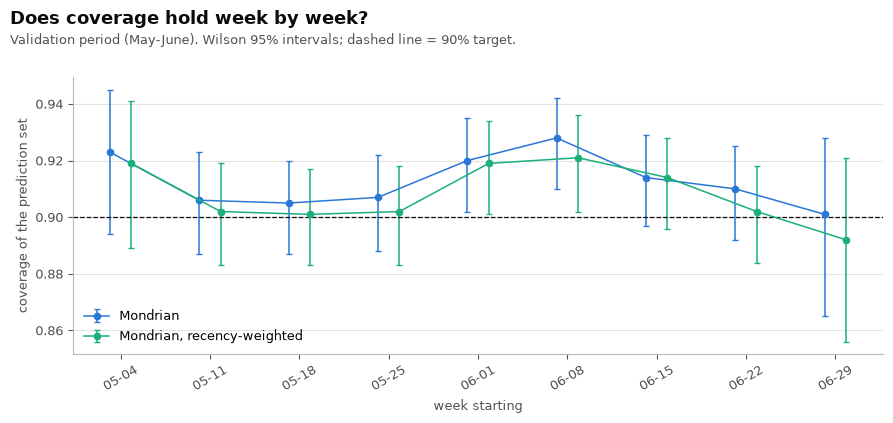

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
fig.subplots_adjust(top=0.82, left=0.08, right=0.98, bottom=0.16)
weeks = sorted(week.unique())
for offset, (label, colour) in zip((-0.12, 0.12), (('Mondrian', BLUE), ('Mondrian, recency-weighted', AQUA))):
    sub = weekly[weekly['method'] == label].set_index('week').loc[weeks]
    ax.errorbar(np.arange(len(weeks)) + offset, sub['coverage'], yerr=[sub['coverage'] - sub['ci_low'], sub['ci_high'] - sub['coverage']], fmt='o-', color=colour,
                ecolor=colour, elinewidth=1.1, markersize=4.5, capsize=2, linewidth=1.1, label=label)
ax.axhline(1 - MAIN_ALPHA, color=INK, linewidth=0.9, linestyle='--')
ax.set_xticks(range(len(weeks)))
ax.set_xticklabels([w.split('/')[0][5:] for w in weeks], fontsize=9, rotation=30)
ax.set_xlabel('week starting', color=MUTED, fontsize=9)
ax.set_ylabel('coverage of the prediction set', color=MUTED, fontsize=9)
style(ax, 'y')
ax.legend(frameon=False, fontsize=9, loc='lower left')
fig.text(0.01, 0.98, 'Does coverage hold week by week?', fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.925, 'Validation period (May-June). Wilson 95% intervals; dashed line = 90% target.', fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase8_weekly_coverage.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Coverage per subgroup (target 90%)
Overall and abusive-class coverage inside every group. A group with fewer than 100 abusive requests is marked "too few to judge" for the abusive class, because its interval is too wide to say anything.

In [14]:
subgroup_rows = []
for name, mask in groups.items():
    mask = np.asarray(mask)
    for label, sets in (('marginal split', sets_marg), ('Mondrian', sets_mond), ('Mondrian, recency-weighted', sets_weighted)):
        hit = sets[np.arange(len(y_test4)), y_test4][mask]
        low, high = wilson_interval(hit.sum(), int(mask.sum()))
        abusive_mask = mask & (y_test4 == AB)
        ab_hit = sets[abusive_mask, AB]
        ab_low, ab_high = wilson_interval(ab_hit.sum(), int(abusive_mask.sum()))
        subgroup_rows.append({'group': name, 'method': label, 'requests': int(mask.sum()), 'coverage': hit.mean(), 'ci_low': low, 'ci_high': high,
                              'avg_set_size': float(sets[mask].sum(axis=1).mean()), 'abusive_n': int(abusive_mask.sum()), 'abusive_coverage': ab_hit.mean(),
                              'abusive_ci_low': ab_low, 'abusive_ci_high': ab_high,
                              'abusive_note': 'too few to judge' if abusive_mask.sum() < 100 else 'ok'})
subgroups = pd.DataFrame(subgroup_rows).round(3)
subgroups.to_csv(REPORTS / 'phase8_subgroup_coverage.csv', index=False)
mondrian_view = subgroups[subgroups['method'] == 'Mondrian'].set_index('group').loc[list(groups)]
below = mondrian_view[mondrian_view['ci_high'] < 1 - MAIN_ALPHA]
print('Mondrian subgroups whose whole 95% interval lies below the 90% target:', list(below.index) if len(below) else 'none')
mondrian_view[['requests', 'coverage', 'ci_low', 'ci_high', 'avg_set_size', 'abusive_n', 'abusive_coverage', 'abusive_ci_low', 'abusive_ci_high', 'abusive_note']]

Mondrian subgroups whose whole 95% interval lies below the 90% target: none


,requests,coverage,ci_low,ci_high,avg_set_size,abusive_n,abusive_coverage,abusive_ci_low,abusive_ci_high,abusive_note
group,,,,,,,,,,
customer: new (< 90 days),1111,0.919,0.901,0.934,1.287,90,0.956,0.891,0.983,too few to judge
customer: established,7386,0.912,0.905,0.918,1.294,609,0.938,0.916,0.954,ok
order value: low third,2624,0.920,0.909,0.930,1.343,191,0.901,0.850,0.935,ok
order value: middle third,2942,0.910,0.899,0.920,1.282,229,0.934,0.895,0.960,ok
order value: high third,2931,0.908,0.897,0.918,1.260,279,0.971,0.944,0.985,ok
text: English-like,4440,0.917,0.909,0.925,1.275,383,0.935,0.905,0.955,ok
text: Hinglish-like (mixed),1726,0.921,0.908,0.933,1.329,127,0.969,0.922,0.988,ok
text: Hindi-dominant,2331,0.897,0.884,0.909,1.301,189,0.931,0.886,0.959,ok
month: May,3729,0.908,0.898,0.917,1.299,320,0.925,0.891,0.949,ok


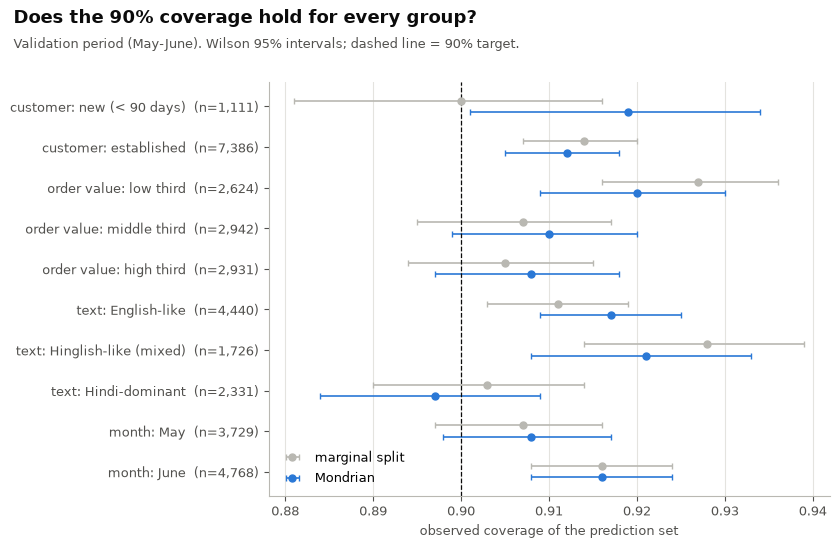

In [15]:
order = list(groups)
fig, ax = plt.subplots(figsize=(8.5, 5.6))
fig.subplots_adjust(top=0.85, left=0.31, right=0.97, bottom=0.11)
for offset, (label, colour) in zip((0.14, -0.14), (('marginal split', GREY), ('Mondrian', BLUE))):
    sub = subgroups[subgroups['method'] == label].set_index('group').loc[order]
    positions = np.arange(len(order))[::-1] + offset
    ax.errorbar(sub['coverage'], positions, xerr=[sub['coverage'] - sub['ci_low'], sub['ci_high'] - sub['coverage']], fmt='o', color=colour, ecolor=colour,
                elinewidth=1.2, markersize=5, capsize=2, label=label)
ax.axvline(1 - MAIN_ALPHA, color=INK, linewidth=0.9, linestyle='--')
ax.set_yticks(np.arange(len(order))[::-1])
ax.set_yticklabels([f'{g}  (n={int(mondrian_view.loc[g, "requests"]):,})' for g in order], fontsize=9)
ax.set_xlabel('observed coverage of the prediction set', color=MUTED, fontsize=9)
style(ax, 'x')
ax.legend(frameon=False, fontsize=9, loc='lower left')
fig.text(0.01, 0.98, 'Does the 90% coverage hold for every group?', fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.93, 'Validation period (May-June). Wilson 95% intervals; dashed line = 90% target.', fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase8_subgroup_coverage.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. What the prediction sets look like, and how they feed Phase 9
The most common sets (Mondrian, 90% target), and a simple ambiguity flag: a set that contains `abusive` together with another class means "closer review". This is information for the Phase 9 router, not a decision yet; the router still computes expected cost from the calibrated probabilities under the official matrix (escalate a genuine customer 10, approve an abusive request 1, inspect 0.5 or 0.3).

In [16]:
labels_mond = np.array(set_labels(sets_mond))
set_table = (pd.DataFrame({'set': labels_mond, 'abusive': y_test})
             .groupby('set').agg(requests=('abusive', 'size'), abusive_rate=('abusive', 'mean')).sort_values('requests', ascending=False))
set_table['share'] = set_table['requests'] / len(y_test)
set_table.head(8).round(3)

,requests,abusive_rate,share
set,,,
{genuine_fit_issue},3340,0.003,0.393
"{abusive, genuine_quality_issue}",1669,0.084,0.196
{abusive},994,0.465,0.117
{genuine_wrong_item},867,0.020,0.102
{genuine_quality_issue},804,0.020,0.095
"{abusive, genuine_fit_issue}",594,0.047,0.070
"{abusive, genuine_wrong_item}",229,0.118,0.027


In [17]:
has_abusive = sets_mond[:, AB]
size = sets_mond.sum(axis=1)
kind = np.where(has_abusive & (size == 1), 'only {abusive}', np.where(has_abusive, 'abusive with other classes (ambiguous)', 'no abusive in the set'))
flag_table = (pd.DataFrame({'set kind': kind, 'abusive': y_test}).groupby('set kind')
              .agg(requests=('abusive', 'size'), abusive_found=('abusive', 'sum'), abusive_rate=('abusive', 'mean')))
flag_table['share_of_requests'] = flag_table['requests'] / len(y_test)
flag_table['share_of_all_abusive'] = flag_table['abusive_found'] / y_test.sum()
flag_table.round(3)

,requests,abusive_found,abusive_rate,share_of_requests,share_of_all_abusive
set kind,,,,,
abusive with other classes (ambiguous),2492,195,0.078,0.293,0.279
no abusive in the set,5011,42,0.008,0.590,0.060
only {abusive},994,462,0.465,0.117,0.661


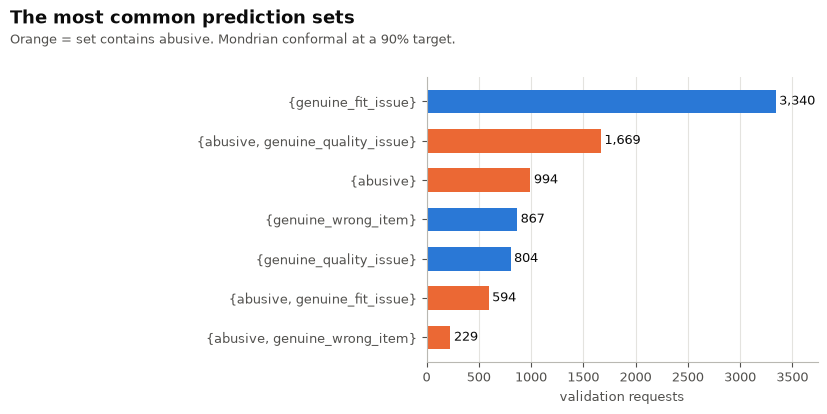

In [18]:
top = set_table.head(8)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
fig.subplots_adjust(top=0.82, left=0.5, right=0.96, bottom=0.14)
colours = [ORANGE if 'abusive' in s else BLUE for s in top.index]
bars = ax.barh(top.index[::-1], top['requests'].to_numpy()[::-1], color=colours[::-1], height=0.6)
for bar, value in zip(bars, top['requests'].to_numpy()[::-1]):
    ax.text(bar.get_width() + top['requests'].max() * 0.01, bar.get_y() + bar.get_height() / 2, f'{value:,}', va='center', fontsize=9, color=INK)
ax.set_xlim(0, top['requests'].max() * 1.12)
ax.set_xlabel('validation requests', color=MUTED, fontsize=9)
style(ax, 'x')
fig.text(0.01, 0.98, 'The most common prediction sets', fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.925, 'Orange = set contains abusive. Mondrian conformal at a 90% target.', fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase8_prediction_sets.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Save calibrated probabilities, uncertainty and configuration

In [19]:
joblib.dump(final_calibrator, MODELS / 'final_abuse_calibrator.joblib')
for member_name, (_, _, fitted_model) in fitted_members.items():
    if member_name == 'catboost':
        fitted_model.save_model(str(MODELS / 'catboost_seed0.cbm'))
    elif fitted_model is not None:
        fitted_model.booster_.save_model(str(MODELS / f'{member_name}_seed0.txt'))
predictions = parts['test'][['return_id', 'label']].reset_index(drop=True)
for index, label in enumerate(LABELS):
    predictions[f'p_{label}_calibrated'] = four_cal[:, index]
predictions['p_abusive_raw'] = raw_test
predictions['p_abusive_calibrated'] = p_test_cal
predictions['prediction_set_mondrian'] = labels_mond
predictions['prediction_set_marginal'] = set_labels(sets_marg)
predictions['prediction_set_mondrian_recency'] = set_labels(sets_weighted)
predictions['set_size_mondrian'] = size
predictions['ambiguous_abusive_flag'] = has_abusive & (size > 1)
predictions['decision_preview_cost_router'] = route(p_test_cal, cfg)
predictions.to_csv(REPORTS / 'phase8_validation_predictions.csv', index=False)
record = {
    'final_model': final_model_name, 'based_on': 'reports/phase7_config.json', 'members': dict(zip(member_names, member_weights.round(4).tolist())),
    'seeds': list(SEEDS), 'main_seed': 0,
    'calibrator_candidates': list(LABEL_TO_METHOD), 'chosen_calibrator': chosen,
    'calibrator_rule': 'chosen on the calibration part by 5-fold cross-fitting: lowest Brier; calibrators within 0.0005 are tied and the best official score of the routing wins',
    'calibrator_choice_reason': reason, 'calibrator_fitted_on': 'calibration part only (10% chronological split)',
    'conformal': {'score': '1 - P(true class) from calibrated four-class probabilities', 'main_alpha': MAIN_ALPHA, 'alphas': list(ALPHAS),
                  'variants': list(VARIANTS), 'recency_half_life_days': HALF_LIFE_DAYS,
                  'calibration_scores': '5-fold cross-fitted calibrated probabilities on the calibration part',
                  'thresholds_marginal_main_alpha': [float(t) for t in th_marg], 'thresholds_mondrian_main_alpha': dict(zip(LABELS, [float(t) for t in th_mond])),
                  'thresholds_mondrian_recency_main_alpha': dict(zip(LABELS, [float(t) for t in th_weighted])),
                  'empty_sets': 'receive the most probable class; coverage before the fix is reported'},
    'subgroups': {'tenure': f"new if tenure < {cfg['fairness']['new_customer_days']} days", 'order_value': 'terciles of the TRAIN order values',
                  'language': 'word-list heuristic, three groups (English-like, Hinglish-like mixed, Hindi-dominant); not a language identifier'},
    'hidden_test_labels_used': False, 'versions': versions}
(REPORTS / 'phase8_config.json').write_text(json.dumps(record, indent=2, default=str))
(MODELS / 'calibration_conformal_config.json').write_text(json.dumps(record, indent=2, default=str))
print(sorted(p.name for p in REPORTS.glob('phase8_*')), '|', sorted(p.name for p in MODELS.glob('*')))

['phase8_calibration_comparison.csv', 'phase8_calibrator_selection_calibration_part.csv', 'phase8_config.json', 'phase8_conformal_summary.csv', 'phase8_group_calibration.csv', 'phase8_score_drift.csv', 'phase8_subgroup_coverage.csv', 'phase8_validation_predictions.csv', 'phase8_weekly_coverage.csv'] | ['calibration_conformal_config.json', 'catboost_seed0.cbm', 'final_abuse_calibrator.joblib']


## 11. Limitations that remain
What this notebook addresses: the calibrator is chosen on the calibration part (not the reported window), three seeds are reported, a smoother calibrator is tried, drift is measured (score shifts, weekly coverage, a recency-weighted variant), the empty-set effect is shown, group calibration is flagged, and language has three heuristic groups. What it cannot remove:
- **One validation window** (about 700 abusive requests): the weekly and subgroup intervals are wide, and a gain smaller than the interval is not evidence. More labelled data from a later period would be needed to do better.
- **A small calibration part** (about 290 abusive requests): the bagged calibrator and cross-fitting reduce overfitting but cannot add data. A group with fewer than 100 abusive requests cannot be judged for abusive coverage.
- **The coverage guarantee needs similar data.** The chronological split means calibration and later data are not exactly exchangeable; the drift checks show the size of the shift here, but July-September is not available, so its behaviour is unknown. Keep monitoring coverage by week once labels arrive.
- **The recency-weighted variant is approximate:** its guarantee is weaker than plain split conformal's, so it is reported as a sensitivity check, not a replacement.
- **The language groups are heuristic.** The word list is incomplete and there is no ground-truth language label, so the three groups indicate rather than identify English, Hinglish and transliterated Hindi.
- **Group calibration is flagged, not enforced.** Separate calibrators per group would use group membership in the decision, which is a policy choice for Phase 9.
- The final model depends on Phase 7: if the Phase 7 verdict changes, rerun this notebook.

## 12. Completion checklist

In [20]:
checklist = {
    'Built on the Phase 7 final model': config7_path.exists() and final_model_name == config7['final_model'],
    'Three seeds reported': len(seed_table) == len(SEEDS) + 2,
    'Calibrator chosen on the calibration part, not on the validation window': (REPORTS / 'phase8_calibrator_selection_calibration_part.csv').exists(),
    'Platt, isotonic and bagged isotonic compared': set(calibrators) == set(LABEL_TO_METHOD),
    'Brier score, ECE and reliability plot reported': {'brier', 'ece'} <= set(calibration_table.columns) and (FIG / 'phase8_reliability.png').exists(),
    'Calibration checked inside each customer group': (REPORTS / 'phase8_group_calibration.csv').exists(),
    'Three conformal variants at three error levels': len(conformal_table) == 9,
    'Coverage with and without the empty-set fix': 'coverage_before_empty_fix' in conformal_table,
    'Drift checked: score shift, weekly coverage, recency-weighted variant': (REPORTS / 'phase8_score_drift.csv').exists() and (REPORTS / 'phase8_weekly_coverage.csv').exists(),
    'Coverage reported per class, per month and per subgroup': len(per_class) == 4 and {'month: May', 'month: June'} <= set(groups),
    'Three language groups (heuristic)': {'text: English-like', 'text: Hinglish-like (mixed)', 'text: Hindi-dominant'} <= set(groups),
    'Abusive coverage per subgroup with a too-few-to-judge flag': 'abusive_note' in subgroups,
    'Calibrated probabilities and sets saved': (REPORTS / 'phase8_validation_predictions.csv').exists(),
    'Calibrator and configuration saved': (MODELS / 'final_abuse_calibrator.joblib').exists() and (REPORTS / 'phase8_config.json').exists(),
    'July-September labels untouched': 'label' not in data['test'].columns,
}
not_done = [k for k, v in checklist.items() if not v]
assert not not_done, not_done
print('all', len(checklist), 'items done')

all 15 items done
